# Notebook 2 -- Feature Extraction

**Purpose:** Extract raster-derived features for each drop polygon side. Covers three parts:

- **Part 1:** DOB (Day of Burning) local buffer -- when pixels burned relative to drop date
- **Part 2:** Raster split -- whole-fire burn comparison across an extended drop line (biggest accuracy driver)
- **Part 3:** Additional feature engineering explored: distance to unburned pixels and expanded polygon to experiment on a middle ground between local buffer and whole raster. 

**Input:** `drops_clean.geojson` (from Notebook 1)

**Key outputs:**
- `training_features_dob.csv`
- `training_features_split.csv`
- `training_features_dist.csv`


In [5]:
# ---- Imports ----
import geopandas as gpd
import rasterio
import os
import numpy as np
import pandas as pd
from rasterio.mask import mask
from scipy import stats as scipy_stats
import matplotlib.pyplot as plt
import rasterio.plot


In [6]:
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
RAW, INTERIM, FEATS, MODELS, OUT = (ROOT / p for p in
    ["data/raw", "data/interim", "data/features", "models", "outputs"])
INTERIM.mkdir(parents=True, exist_ok=True)

In [7]:
# Loading clean drops that were saved in Notebook 1. 
drops = gpd.read_file(INTERIM / "drops_clean.geojson")
print(f"Loaded {len(drops)} drop sides across {drops['Evnt_ID'].nunique()} fires")

Loaded 21234 drop sides across 424 fires


# Part 1: DOB Feature Extraction

For each drop side polygon, we sample the DOB raster underneath it and compute burn-day statistics relative to the drop date (converted to day-of-year)

**Key features extracted:**
- `mean_dob`/`median_dob` -- average burn day across all burned pixels
- `early_pixels` - pixels that burned BEFORE the drop (fire origin signal)
- `late_pixels` -- pixels that burned AFTER the drop (protected side signal)
- `unburned_pixels` -- pixels that never burned (protected side signal)
- `burned_pixels`/`total_pixels` -- overall burn coverage

In [8]:
# Open the tif file of the fire and extract pixels under the drop polygon. 
def extract_pixel_stats(geometry, tif_path, drop_doy, nodata_val=65535):
    try:
        with rasterio.open(tif_path) as src:
            #crop=True will prevent from loading the whole raster but only the polygon under the drop. 
            #filled=True will make sure that the pixels inside the bounding box but outside the drop polygon are set to nodata, so that only the pixels inside the polygon are counted as valid burn-day values. 
            # nodata_val=65535 - this variable represents the pixels which never burnt. 
            out_image, _ = mask(src, [geometry], crop=True, filled=True, nodata=nodata_val)

            #usually returns (band, cols, rows). since it is 2d, we will take [0]

            pixels = out_image[0]

    except Exception as e:
        return None
    


    # filter out pixels that burned. valid is a 1D array that has the doy of the burns. 
    valid = pixels[pixels != nodata_val]



    # This is for the edge cases where no pixels under the polygons burned. return NaN for DOB stats and 0 for all pixels counts. unburned_pixels and total_pixels are still meaningful. 
    if len(valid) == 0:
        return {
            "mean_dob" : np.nan, "median_dob":np.nan, 
            "early_pixels": 0, "late_pixels":0,
            "unburned_pixels": int(np.sum(pixels == nodata_val)), 
            "total_pixels" : int(pixels.size), "burned_pixels":0
        }
    

    # Normal case where at least some pixels under the drop burned. 
    return {
        # average and median burn day across all pixels. 
        "mean_dob": float(np.mean(valid)), 
        "median_dob": float(np.median(valid)),

        # pixels that burned before the drop date. Fire was already here (origin side)
        "early_pixels": int(np.sum(valid < drop_doy)),

        # pixels that burned after the drop date. Fire arrived here later. (protected side)
        "late_pixels": int(np.sum(valid > drop_doy)),
        
        # pixels that never burned at all
        "unburned_pixels" : int(np.sum(pixels == nodata_val)),

        #total pixels in the cropped bounding box (burned+unburned+boundary)
        "total_pixels": int(pixels.size),

        # total burned pixels 
        "burned_pixels": int(len(valid))
    }

In [9]:
# Feature Extraction Loop 
# Iterates over every drop-side row in the shapefile. 
# For each row, samples the DOB raster pixels under that polygon and computes burn-day statistics relative to the burn date. 
# Results are collected in a list of dicts, one per drop side, which is later converted into the training DataFrame. 

rows = [] # Stores one dict per successfully processed drop-side. 
skipped = 0 # tracks rows where extraction failed. 

for idx, drop in drops.iterrows():

    # Extract pixel statistics from the DOB raster under this drop-side polygon. Returns None if any error occurs. 
    stats = extract_pixel_stats(
        geometry=drop.geometry, # polygon shape of the drop side.
        tif_path = drop["tif_path"], # path to this fire's DOB raster
        drop_doy = drop["drop_doy"], # drop date as day-of-year for early/late pixel comparison. 

    )


    # skip this row if extraction failed and count it. 
    if stats is None:
        skipped += 1
        continue


    # Attach identifying and operational metadata from the shapefile row to the raster-derived stats, so each row in the final DataFrame contains both feature values and bookkeeping information. 

    stats.update({
        "event_id": drop["Evnt_ID"], # fire incident ID. Later used for GroupKFold splitting. 
        "buff_id": drop["buff_id"], # which side of the drop (1 or 2)
        "altitude": drop.get("AltFet1", np.nan), # aircraft altitude at the time of drop
        "knots": drop.get("Knots1", np.nan), # aircraft speed at the time of drop
        "gallons": drop.get("Gallns1", np.nan), # volume of retardants dropped
        "drop_seconds": drop.get("DrpScnd", np.nan), # duration of drop in seconds
        "pt": drop["new_pt"], # target variable : 1 = protected side, 0 = origin side. 
        "drop_id" : drop["drop_id"] # unique drop identifier (event_id + lat + long + utcdate) - used to pair two sides of the same drop. 
    })

    rows.append(stats)


# BUILDING THE DATAFRAME

print(f"Processed: {len(rows)}, Skipped: {skipped}")

# Convert list of dicts to DataFrame - one row per drop-side
df_dob = pd.DataFrame(rows)

# Saving the file to CSV so features don't need to be extracted every time. 
df_dob.to_csv(FEATS / "train" / "training_features_dob.csv", index=False)
print(df_dob.head())

Processed: 21081, Skipped: 153
   mean_dob  median_dob  early_pixels  late_pixels  unburned_pixels  \
0     165.0       165.0             0            0               66   
1     165.0       165.0             0            0               67   
2     165.0       165.0             0            0              123   
3     165.0       165.0             0            0              212   
4     165.0       165.0             0            0              173   

   total_pixels  burned_pixels               event_id  buff_id  altitude  \
0           180            114  AZ3143311069520170614      1.0    5738.0   
1           180            113  AZ3143311069520170614      2.0    5738.0   
2           252            129  AZ3143311069520170614      1.0    5659.0   
3           247             35  AZ3143311069520170614      2.0    5659.0   
4           240             67  AZ3143311069520170614      1.0    5780.0   

   knots  gallons drop_seconds  pt  \
0  165.0      0.0           53   1   
1  165.0 

In [9]:
# Running some sanity check to see if our training data shows real signal and the extracted features actually differ between the two classes (protected vs origin)

# If features carry a real signal, pt=1 (protected) should show: 
# - more unburned pixels (protected side less likely to have burned)
# - fewer early pixels (less fire activity before the drop on the protected side)
# - fewer burned pixels (less total fire)


# If the means look nearly identical between pt=0 and pt=1, the features have no discriminative power and model won't learn anything useful. 

df_dob.groupby("pt")[["unburned_pixels", "early_pixels", "late_pixels", "burned_pixels"]].mean()

,unburned_pixels,early_pixels,late_pixels,burned_pixels
pt,,,,
0,181.323516,16.049967,22.596594,89.845394
1,211.656878,4.444232,21.860149,49.332504


In [7]:
# Result confirmed the hypothesis. 
# We can see a clear separation between pt=0 and pt=1, especially in early_pixels. 

In [10]:
# Second Sanity Check
# Each drop should have exactly 2 rows - one per side (buff_id 1 and 2)
# This check verifies that our drop_id construction above correctly groups rows into pairs. 
# Expected result: almost all drop_ids should have exactly two rows. 
print(df_dob.groupby("drop_id").size().value_counts())

2    10239
1      152
4      109
6        2
3        1
Name: count, dtype: int64


# Part 2: Raster Split Feature Extraction

**Motivation**: DOB features sampled only within the small buffered drop polygon showed limited signal -- many drops had nearly identical burn statistics on both sides, and the best DOB-only model plateaued to around 81% accuracy. 


**Approach**: Instead of sampling only the small buffer polygon, extend the drop line across the entire fire's DOB raster and split the whole raster into two halves. Compute pixel statistics on each half (thousands of pixels)

**Hypothesis**: The side with more burned pixel (relative to the whole fire, not just the local buffer) is more likely to be the fire origin side; the side with fewer burned pixels is more likely to be the protected side. 

**Validated visually in QGIS** across multiple random drops before implementation --  the patten held consistently. 

**Result**: This became the single largest driver of model improvement, taking the combined model from ~81% to ~90% accuracy (see Notebook 3). 



In [10]:
# Extend Drop Line Function
from shapely.ops import split as shapely_split, linemerge
from shapely.geometry import LineString, box

def extend_line(line, distance=500000):
    """
    Extend a LineString in both directions far beyond raster bounds
    (distance=500km ensures the line cuts through any CONUS fire raster).
    Handles MultiLineString by merging into a single line first.
    """
    # handle MultiLineString — merge into single LineString
    if line.geom_type == "MultiLineString":
        line = linemerge(line)
        # if merge still gives MultiLineString, take the longest segment
        if line.geom_type == "MultiLineString":
            line = max(line.geoms, key=lambda g: g.length)

    coords = list(line.coords)
    start = np.array(coords[0])
    end = np.array(coords[-1])

    # unit direction vector of the line
    direction = end - start
    direction = direction / np.linalg.norm(direction)

    # extend both endpoints far beyond raster bounds
    new_start = start - direction * distance
    new_end = end + direction * distance

    return LineString([new_start, new_end])

In [11]:
# Split Extraction Function

def extract_split_features(pair, tif_path, nodata_val=65535):
    """
    Split the DOB raster by the drop line and extract pixel stats
    for each half, matched to the correct buff_id.

    pair: GeoDataFrame with exactly 2 rows (both sides of one drop)
    tif_path: path to the fire's DOB raster

    Returns (stats_side1, stats_side2) or None if extraction fails.
    """
    row_1 = pair[pair["buff_id"] == 1].iloc[0]
    row_2 = pair[pair["buff_id"] == 2].iloc[0]
    geom_1 = row_1.geometry
    geom_2 = row_2.geometry

    # get shared boundary between the two polygons = the drop line
    drop_line = geom_1.intersection(geom_2)

    # guard: skip if no shared boundary
    if drop_line.is_empty:
        return None

    # guard: handle GeometryCollection by extracting line components
    if drop_line.geom_type == "GeometryCollection":
        lines = [g for g in drop_line.geoms if "Line" in g.geom_type]
        if not lines:
            return None
        drop_line = linemerge(lines)

    # guard: must be a line geometry at this point
    if drop_line.geom_type not in ["LineString", "MultiLineString"]:
        return None

    # extend the line far beyond the raster bounds
    extended = extend_line(drop_line)

    with rasterio.open(tif_path) as src:
        bounds = src.bounds
        raster_bbox = box(bounds.left, bounds.bottom, bounds.right, bounds.top)

        # split the raster's bounding box into two halves using the extended line
        try:
            result = shapely_split(raster_bbox, extended)
            if len(result.geoms) != 2:
                return None
            half_A, half_B = result.geoms
        except Exception:
            return None

        # match halves to buff_ids using polygon centroids
        # (the split doesn't know which half is 'side 1' vs 'side 2')
        centroid_1 = geom_1.centroid
        if half_A.contains(centroid_1):
            side1_geom, side2_geom = half_A, half_B
        else:
            side1_geom, side2_geom = half_B, half_A

        # sample pixels for each side
        try:
            img_1, _ = mask(src, [side1_geom], crop=True, filled=True, nodata=nodata_val)
            img_2, _ = mask(src, [side2_geom], crop=True, filled=True, nodata=nodata_val)
        except Exception:
            return None

    pixels_1 = img_1[0]
    pixels_2 = img_2[0]

    def compute_stats(pixels, drop_doy, nodata_val):
        valid = pixels[pixels != nodata_val]
        if len(valid) == 0:
            return {
                "split_mean_dob": np.nan,
                "split_early_pixels": 0,
                "split_late_pixels": 0,
                "split_unburned_pixels": int(np.sum(pixels == nodata_val)),
                "split_burned_pixels": 0,
                "split_total_pixels": int(pixels.size)
            }
        return {
            "split_mean_dob":        float(np.mean(valid)),
            "split_early_pixels":    int(np.sum(valid < drop_doy)),
            "split_late_pixels":     int(np.sum(valid > drop_doy)),
            "split_unburned_pixels": int(np.sum(pixels == nodata_val)),
            "split_burned_pixels":   int(len(valid)),
            "split_total_pixels":    int(pixels.size)
        }

    stats_1 = compute_stats(pixels_1, row_1["drop_doy"], nodata_val)
    stats_2 = compute_stats(pixels_2, row_2["drop_doy"], nodata_val)

    stats_1.update({"event_id": row_1["Evnt_ID"], "buff_id": 1, "drop_id": row_1["drop_id"]})
    stats_2.update({"event_id": row_2["Evnt_ID"], "buff_id": 2, "drop_id": row_2["drop_id"]})

    return stats_1, stats_2

In [13]:
# Split Extraction Loop
# Processing one drop pair at a time (need both sides to construct the drop line)

split_rows = []
skipped_split = 0

drop_pairs = drops.groupby("drop_id")

for drop_id, pair in drop_pairs:
    # only process clean pairs (exactly 2 sides, both buff_ids present)
    if len(pair) != 2:
        skipped_split += 1
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        skipped_split += 1
        continue

    tif_path = pair.iloc[0]["tif_path"]
    result = extract_split_features(pair, tif_path)

    if result is None:
        skipped_split += 1
        continue

    stats_1, stats_2 = result
    split_rows.append(stats_1)
    split_rows.append(stats_2)

print(f"Processed: {len(split_rows)} rows ({len(split_rows)//2} drop pairs)")
print(f"Skipped: {skipped_split}")

df_split = pd.DataFrame(split_rows)
df_split.to_csv(FEATS  / "train" / "training_features_split.csv", index=False)
print(df_split.head())

Processed: 20720 rows (10360 drop pairs)
Skipped: 162
   split_mean_dob  split_early_pixels  split_late_pixels  \
0      165.237059                   0                316   
1      165.031311                   0                288   
2      165.057838                   0                604   
3      165.000000                   0                  0   
4      165.000000                2182                  0   

   split_unburned_pixels  split_burned_pixels  split_total_pixels  \
0                   2561                 1333                3894   
1                   6201                 9198               15399   
2                   7434                10443               17877   
3                   1212                   88                1300   
4                  10031                 2182               12213   

                event_id  buff_id  \
0  AZ3143311069520170614        1   
1  AZ3143311069520170614        2   
2  AZ3143311069520170614        1   
3  AZ31433110695201706

In [14]:
# Sanity Check: Class Separation for Split Features
# Merge with DOB features to check against pt labels
df_check = df_dob.merge(df_split, on=["event_id", "buff_id", "drop_id"], how="left")
print(f"Rows with split features: {df_check['split_burned_pixels'].notna().sum()} / {len(df_check)}")
print(df_check.groupby("pt")[["split_burned_pixels", "split_unburned_pixels"]].mean())
# Expect: pt=0 (origin) shows much higher split_burned_pixels than pt=1 (protected)
# This separation should be substantially stronger than the local-buffer DOB features

Rows with split features: 20582 / 21081
    split_burned_pixels  split_unburned_pixels
pt                                            
0         156962.915179          237182.996623
1          56381.894315          165061.375379


### Visual Validation

Before trusting the split numerically, the split geometry was checked visually against the DOB raster for a sample drop -- confirming the extended line cleanly divides the fire and each half is correctly matched to its `buff_id`.

In [21]:
test_drop_id = "WY4304211058720180915_43.10596_-110.22533_2018-09-23 23:08:49 UTC"
pair = drops[drops["drop_id"] == test_drop_id]

geom_1 = pair[pair["buff_id"] == 1].iloc[0].geometry
geom_2 = pair[pair["buff_id"] == 2].iloc[0].geometry
drop_line = geom_1.intersection(geom_2)
extended = extend_line(drop_line)
test_row = pair.iloc[0]

In [16]:
with rasterio.open(test_row["tif_path"]) as src:
    bounds = src.bounds
    raster_bbox = box(bounds.left, bounds.bottom, bounds.right, bounds.top)

result = shapely_split(raster_bbox, extended)
half_A, half_B = result.geoms

centroid_1 = geom_1.centroid
if half_A.contains(centroid_1):
    side1_geom, side2_geom = half_A, half_B
else:
    side1_geom, side2_geom = half_B, half_A

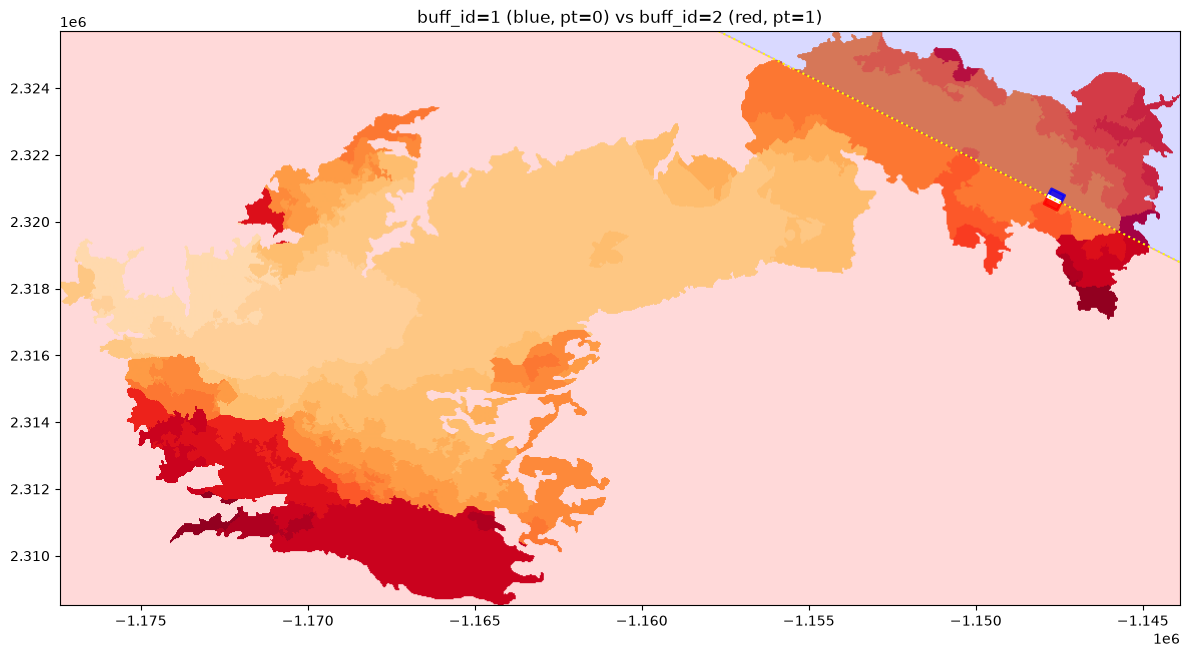

In [17]:
fig, ax = plt.subplots(figsize=(12, 10))

with rasterio.open(test_row["tif_path"]) as src:
    rasterio.plot.show(src, ax=ax, cmap="YlOrRd")
    bounds = src.bounds

ax.set_xlim(bounds.left, bounds.right)
ax.set_ylim(bounds.bottom, bounds.top)

gpd.GeoSeries([side1_geom]).plot(ax=ax, facecolor="blue", alpha=0.15, edgecolor="blue", linewidth=1)
gpd.GeoSeries([side2_geom]).plot(ax=ax, facecolor="red", alpha=0.15, edgecolor="red", linewidth=1)
gpd.GeoSeries([geom_1]).plot(ax=ax, facecolor="blue", alpha=0.8, edgecolor="blue", linewidth=2)
gpd.GeoSeries([geom_2]).plot(ax=ax, facecolor="red", alpha=0.8, edgecolor="red", linewidth=2)
gpd.GeoSeries([drop_line]).plot(ax=ax, color="white", linewidth=3, linestyle="--")
gpd.GeoSeries([extended]).plot(ax=ax, color="yellow", linewidth=1.5, linestyle=":")

ax.set_title(f"buff_id=1 (blue, pt={pair[pair['buff_id']==1]['new_pt'].iloc[0]}) vs buff_id=2 (red, pt={pair[pair['buff_id']==2]['new_pt'].iloc[0]})")
plt.tight_layout()
plt.show()

---
# Part 3: Additional Feature Engineering -- Pushing Past 90%

After presenting the raster-split results (90.1%) to the professor, error analysis revealed two failure modes:

1. **Local buffer vs. raster split disagreement** -- the two feature groups sometimes point in opposite directions (~25% of wrong predictions)
2. **Complex/irregular fire shapes** -- the full-raster split can capture unrelated fire arms that have nothing to do with a specific drop


Hence, I explored new ideas: an expanded (radius-bounded) version of the raster split and distance to unburned pixels from the protected/origin polygons



## 3a -- Distance to Nearest Unburned Area

For each polygon centroid, compute distance to the nearest unburned pixel. Hypothesis: the protected side sits closer to unburned area; the origin side is more deeply surrounded by fire.

In [12]:
import numpy as np
from scipy.ndimage import distance_transform_edt
from shapely.geometry import Point
import rasterio

def compute_dist_to_unburned(tif_path, centroid_1, centroid_2, nodata_val=65535):
    """
    For each polygon centroid, compute distance to nearest unburned pixel.
    Protected side should be CLOSER to unburned area.
    Origin side should be FURTHER from unburned area (surrounded by fire).
    """
    try:
        with rasterio.open(tif_path) as src:
            arr = src.read(1)
            pixel_size = src.res[0]  # meters per pixel

            # binary mask: True = burned, False = unburned
            burned_mask = (arr != nodata_val).astype(np.uint8)

            # distance transform on burned mask
            # gives each burned pixel its distance to nearest unburned pixel
            dist_to_unburned = distance_transform_edt(burned_mask) * pixel_size

            # sample distance at each polygon centroid
            row_1, col_1 = src.index(centroid_1.x, centroid_1.y)
            row_2, col_2 = src.index(centroid_2.x, centroid_2.y)

            # clamp to raster bounds just in case
            row_1 = np.clip(row_1, 0, arr.shape[0]-1)
            col_1 = np.clip(col_1, 0, arr.shape[1]-1)
            row_2 = np.clip(row_2, 0, arr.shape[0]-1)
            col_2 = np.clip(col_2, 0, arr.shape[1]-1)

            dist_1 = float(dist_to_unburned[row_1, col_1])
            dist_2 = float(dist_to_unburned[row_2, col_2])

            return dist_1, dist_2

    except Exception as e:
        return None, None

In [23]:
# use our known test pair from earlier
test_drop_id = df_dob["drop_id"].iloc[0]
pair = drops[drops["drop_id"] == test_drop_id]

geom_1 = pair[pair["buff_id"] == 1].iloc[0].geometry
geom_2 = pair[pair["buff_id"] == 2].iloc[0].geometry
tif_path = pair.iloc[0]["tif_path"]

centroid_1 = geom_1.centroid
centroid_2 = geom_2.centroid

dist_1, dist_2 = compute_dist_to_unburned(tif_path, centroid_1, centroid_2)

pt_1 = pair[pair["buff_id"] == 1]["new_pt"].iloc[0]
pt_2 = pair[pair["buff_id"] == 2]["new_pt"].iloc[0]

print(f"buff_id=1 (pt={pt_1}): distance to unburned = {dist_1:.1f}m")
print(f"buff_id=2 (pt={pt_2}): distance to unburned = {dist_2:.1f}m")
print(f"Hypothesis check: protected side closer to unburned? "
      f"{'Holds' if (pt_1==1 and dist_1 < dist_2) or (pt_2==1 and dist_2 < dist_1) else 'does not hold'}")

buff_id=1 (pt=1): distance to unburned = 150.0m
buff_id=2 (pt=0): distance to unburned = 84.9m
Hypothesis check: protected side closer to unburned? does not hold


In [20]:
# build a quick sample across 100 drops to check overall signal
results = []
drop_pairs = drops.groupby("drop_id")

count = 0
for drop_id, pair in drop_pairs:
    if len(pair) != 2:
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        continue

    geom_1 = pair[pair["buff_id"] == 1].iloc[0].geometry
    geom_2 = pair[pair["buff_id"] == 2].iloc[0].geometry
    tif_path = pair.iloc[0]["tif_path"]
    pt_1 = pair[pair["buff_id"] == 1]["new_pt"].iloc[0]

    dist_1, dist_2 = compute_dist_to_unburned(tif_path, geom_1.centroid, geom_2.centroid)

    if dist_1 is None:
        continue

    results.append({
        "drop_id": drop_id,
        "dist_1": dist_1,
        "dist_2": dist_2,
        "pt_1": pt_1,
        "hypothesis_holds": (dist_1 < dist_2) == (pt_1 == 1)
    })

    count += 1
    if count >= 100:
        break

df_check = pd.DataFrame(results)
print(f"Hypothesis holds: {df_check['hypothesis_holds'].mean():.1%} of 100 drops")

Hypothesis holds: 75.0% of 100 drops


In [21]:
from tqdm import tqdm

dist_rows = []
skipped = 0

drop_pairs = drops.groupby("drop_id")
drop_pairs_list = list(drops.groupby("drop_id"))


for drop_id, pair in tqdm(drop_pairs_list, desc="Distance extraction"):
    if len(pair) != 2:
        skipped += 1
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        skipped += 1
        continue

    tif_path = pair.iloc[0]["tif_path"]
    
    row_1 = pair[pair["buff_id"] == 1].iloc[0]
    row_2 = pair[pair["buff_id"] == 2].iloc[0]
    
    centroid_1 = row_1.geometry.centroid
    centroid_2 = row_2.geometry.centroid

    dist_1, dist_2 = compute_dist_to_unburned(
        tif_path, centroid_1, centroid_2
    )

    if dist_1 is None:
        skipped += 1
        continue

    dist_rows.append({
        "event_id": row_1["Evnt_ID"],
        "buff_id": 1,
        "drop_id": drop_id,
        "dist_to_unburned": dist_1
    })
    dist_rows.append({
        "event_id": row_2["Evnt_ID"],
        "buff_id": 2,
        "drop_id": drop_id,
        "dist_to_unburned": dist_2
    })

print(f"Processed: {len(dist_rows)} rows, Skipped: {skipped}")
df_dist = pd.DataFrame(dist_rows)
df_dist.to_csv(FEATS / "train" / "training_features_dist.csv", index=False)

Distance extraction: 100%|██████████| 10522/10522 [07:10<00:00, 24.42it/s]


Processed: 20730 rows, Skipped: 157


In [22]:
print(df_dist.shape)
print(df_dist["dist_to_unburned"].describe())
print(df_dist["dist_to_unburned"].isna().sum())


(20730, 4)
count    20730.000000
mean       430.181019
std        900.639219
min          0.000000
25%          0.000000
50%         84.852814
75%        400.249922
max       9003.249413
Name: dist_to_unburned, dtype: float64
0


In [23]:
# merge with existing features to get pt labels
df_check = df_dist.merge(df_dob[["event_id","buff_id","drop_id","pt"]], 
                          on=["event_id","buff_id","drop_id"], how="left")
print(df_check.groupby("pt")["dist_to_unburned"].mean())

pt
0.0    467.674972
1.0    398.026036
Name: dist_to_unburned, dtype: float64


In [24]:
df_dist["dist_pair_diff"] = df_dist.groupby("drop_id")["dist_to_unburned"].transform(
    lambda x: x - x.mean()
)
# positive = further from unburned than sibling = likely origin
# negative = closer to unburned than sibling = likely protected

## 3b -- Expanded Polygon (Strongest New Signal)

Instead of splitting the *entire* raster (which can pull in unrelated fire arms for irregularly-shaped fires), constrain the split to a radius around the drop center (25% of the raster diagonal). This keeps thousands of pixels of context per side while staying locally relevant to the specific drop.

In [13]:
def extract_expanded_polygon_features(pair, tif_path, 
                                       radius_fraction=0.25, 
                                       nodata_val=65535):
    """
    Instead of splitting the entire raster, expand each drop polygon
    to cover ~25% of the raster diagonal on its respective side.
    This avoids capturing irrelevant fire arms from complex fire shapes.
    """
    row_1 = pair[pair["buff_id"] == 1].iloc[0]
    row_2 = pair[pair["buff_id"] == 2].iloc[0]
    geom_1 = row_1.geometry
    geom_2 = row_2.geometry
    drop_doy = row_1["drop_doy"]

    drop_line = geom_1.intersection(geom_2)
    if drop_line.is_empty:
        return None

    if drop_line.geom_type == "GeometryCollection":
        from shapely.ops import linemerge
        lines = [g for g in drop_line.geoms if "Line" in g.geom_type]
        if not lines:
            return None
        drop_line = linemerge(lines)

    if drop_line.geom_type not in ["LineString", "MultiLineString"]:
        return None

    extended = extend_line(drop_line)

    with rasterio.open(tif_path) as src:
        bounds = src.bounds

        # compute raster diagonal : determines expansion radius
        raster_diagonal = ((bounds.right - bounds.left)**2 + 
                           (bounds.top - bounds.bottom)**2) ** 0.5
        radius = raster_diagonal * radius_fraction

        # split raster bounding box
        raster_bbox = box(bounds.left, bounds.bottom, bounds.right, bounds.top)
        try:
            result = shapely_split(raster_bbox, extended)
            if len(result.geoms) != 2:
                return None
            half_A, half_B = result.geoms
        except Exception:
            return None

        # match halves to buff_ids
        centroid_1 = geom_1.centroid
        if half_A.contains(centroid_1):
            side1_geom, side2_geom = half_A, half_B
        else:
            side1_geom, side2_geom = half_B, half_A

        # expand: intersect each half with a circle around drop center
        drop_center = drop_line.centroid
        local_buffer = drop_center.buffer(radius)

        side1_local = side1_geom.intersection(local_buffer)
        side2_local = side2_geom.intersection(local_buffer)

        if side1_local.is_empty or side2_local.is_empty:
            return None

        # sample pixels in expanded local areas
        try:
            img_1, _ = mask(src, [side1_local], crop=True, 
                           filled=True, nodata=nodata_val)
            img_2, _ = mask(src, [side2_local], crop=True, 
                           filled=True, nodata=nodata_val)
        except Exception:
            return None

    pixels_1 = img_1[0]
    pixels_2 = img_2[0]

    def compute_stats(pixels, drop_doy, nodata_val):
        valid = pixels[pixels != nodata_val]
        if len(valid) == 0:
            return {
                "exp_mean_dob": np.nan,
                "exp_burned_pixels": 0,
                "exp_unburned_pixels": int(np.sum(pixels == nodata_val)),
                "exp_early_pixels": 0,
                "exp_late_pixels": 0,
                "exp_total_pixels": int(pixels.size)
            }
        return {
            "exp_mean_dob":       float(np.mean(valid)),
            "exp_burned_pixels":  int(len(valid)),
            "exp_unburned_pixels": int(np.sum(pixels == nodata_val)),
            "exp_early_pixels":   int(np.sum(valid < drop_doy)),
            "exp_late_pixels":    int(np.sum(valid > drop_doy)),
            "exp_total_pixels":   int(pixels.size)
        }

    stats_1 = compute_stats(pixels_1, drop_doy, nodata_val)
    stats_2 = compute_stats(pixels_2, drop_doy, nodata_val)

    stats_1.update({"event_id": row_1["Evnt_ID"], 
                    "buff_id": 1, 
                    "drop_id": row_1["drop_id"]})
    stats_2.update({"event_id": row_2["Evnt_ID"], 
                    "buff_id": 2, 
                    "drop_id": row_2["drop_id"]})

    return stats_1, stats_2

In [26]:
test_drop_id = drops["drop_id"].iloc[0]
pair = drops[drops["drop_id"] == test_drop_id]

result = extract_expanded_polygon_features(pair, pair.iloc[0]["tif_path"])

if result:
    stats_1, stats_2 = result
    pt_1 = pair[pair["buff_id"] == 1]["new_pt"].iloc[0]
    pt_2 = pair[pair["buff_id"] == 2]["new_pt"].iloc[0]

    print(f"buff_id=1 (pt={pt_1}): burned={stats_1['exp_burned_pixels']}, "
          f"unburned={stats_1['exp_unburned_pixels']}, "
          f"early={stats_1['exp_early_pixels']}")
    print(f"buff_id=2 (pt={pt_2}): burned={stats_2['exp_burned_pixels']}, "
          f"unburned={stats_2['exp_unburned_pixels']}, "
          f"early={stats_2['exp_early_pixels']}")
    print(f"Total pixels per side: {stats_1['exp_total_pixels']} vs {stats_2['exp_total_pixels']}")
else:
    print("Failed")

buff_id=1 (pt=1): burned=878, unburned=684, early=0
buff_id=2 (pt=0): burned=2013, unburned=1821, early=0
Total pixels per side: 1562 vs 3834


In [27]:
results = []
count = 0

for drop_id, pair in drops.groupby("drop_id"):
    if len(pair) != 2:
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        continue

    result = extract_expanded_polygon_features(pair, pair.iloc[0]["tif_path"])
    if result is None:
        continue

    stats_1, stats_2 = result
    pt_1 = pair[pair["buff_id"] == 1]["new_pt"].iloc[0]

    hypothesis_holds = (pt_1 == 1) == (stats_1["exp_burned_pixels"] < stats_2["exp_burned_pixels"])
    results.append({"holds": hypothesis_holds})

    count += 1
    if count >= 500:
        break

df_check = pd.DataFrame(results)
print(f"Hypothesis holds: {df_check['holds'].mean():.1%} of 500 drops")

Hypothesis holds: 83.8% of 500 drops


In [28]:
from tqdm import tqdm

exp_rows = []
skipped = 0

drop_pairs_list = list(drops.groupby("drop_id"))

for drop_id, pair in tqdm(drop_pairs_list, desc="Expanded polygon extraction"):
    if len(pair) != 2:
        skipped += 1
        continue
    if set(pair["buff_id"].astype(int)) != {1, 2}:
        skipped += 1
        continue

    tif_path = pair.iloc[0]["tif_path"]
    result = extract_expanded_polygon_features(pair, tif_path)

    if result is None:
        skipped += 1
        continue

    stats_1, stats_2 = result
    exp_rows.append(stats_1)
    exp_rows.append(stats_2)

print(f"Processed: {len(exp_rows)} rows, Skipped: {skipped}")
df_exp = pd.DataFrame(exp_rows)
df_exp.to_csv(FEATS / "train" /  "training_features_expanded.csv", index=False)

Expanded polygon extraction: 100%|██████████| 10522/10522 [02:16<00:00, 77.34it/s] 


Processed: 20716 rows, Skipped: 164


In [30]:
# quick class separation check
df_check = df_exp.merge(
    pd.read_csv(FEATS / "train" / "training_features_dob.csv")[["event_id","buff_id","drop_id","pt"]],
    on=["event_id","buff_id","drop_id"],
    how="left"
)
print(df_check.groupby("pt")[["exp_burned_pixels","exp_unburned_pixels","exp_early_pixels"]].mean())

     exp_burned_pixels  exp_unburned_pixels  exp_early_pixels
pt                                                           
0.0       56945.317024         72673.395773      29221.952422
1.0       23671.485077         71389.030825       8180.719151


#### Part 4: Wind

In [1]:
import xarray as xr
from pyproj import Transformer

In [31]:
from rasterio.warp import transform as rio_transform

def to_lonlat(x, y):
    lon, lat = rio_transform("EPSG:5070", "EPSG:4326", [x], [y])
    return lon[0], lat[0]

def load_grid(folder, prefix, var, years = (2017,2018,2019)):
    out = {}
    for y in years:
        a = xr.open_dataset(RAW / folder / f"{prefix}_{y}.nc")[var]
        out[y] = (a.values, a.lat.values, a.lon.values, pd.DatetimeIndex(a.day.values))

    return out


In [14]:
th_grid = load_grid("th", "th", "wind_from_direction")
vs_grid = load_grid("vs", "vs", "wind_speed")

In [17]:
def sample_grid(grid, lon, lat, date):
    arr, lats, lons, days = grid[date.year]
    i = np.abs(lats-lat).argmin()
    j = np.abs(lons-lon).argmin()
    return float(arr[days.get_loc(date), i, j])


_bounds_cache = {}
def get_bounds(path):
    if path not in _bounds_cache:
        with rasterio.open(path) as src:
            _bounds_cache[path] = src.bounds
    return _bounds_cache[path]

In [32]:
def extract_wind_features(pair, radius_fraction=0.25, return_geoms=False):
    row_1 = pair[pair["buff_id"] == 1].iloc[0]
    row_2 = pair[pair["buff_id"] == 2].iloc[0]
    geom_1, geom_2 = row_1.geometry, row_2.geometry

    # drop line = shared boundary of the two buffer polygons
    drop_line = geom_1.intersection(geom_2)
    if drop_line.is_empty:
        return None
    if drop_line.geom_type == "GeometryCollection":
        lines = [g for g in drop_line.geoms if "Line" in g.geom_type]
        if not lines:
            return None
        drop_line = linemerge(lines)
    if drop_line.geom_type not in ["LineString", "MultiLineString"]:
        return None
    extended = extend_line(drop_line)

    bounds = get_bounds(row_1["tif_path"])
    raster_bbox = box(bounds.left, bounds.bottom, bounds.right, bounds.top)
    radius = ((bounds.right - bounds.left) ** 2 + (bounds.top - bounds.bottom) ** 2) ** 0.5 * radius_fraction

    # split the raster by the extended line, match halves to buff_ids by centroid
    try:
        result = shapely_split(raster_bbox, extended)
        if len(result.geoms) != 2:
            return None
        half_A, half_B = result.geoms
    except Exception:
        return None
    if half_A.contains(geom_1.centroid):
        side1_geom, side2_geom = half_A, half_B
    else:
        side1_geom, side2_geom = half_B, half_A

    # same expanded regions as the DOB expanded-polygon features
    center = drop_line.centroid
    local_buffer = center.buffer(radius)
    side1_local = side1_geom.intersection(local_buffer)
    side2_local = side2_geom.intersection(local_buffer)
    if side1_local.is_empty or side2_local.is_empty:
        return None

    # unit normal of the drop line, oriented toward side 1; side 2 gets the opposite
    (x0, y0), (x1, y1) = extended.coords[0], extended.coords[-1]
    d = np.array([x1 - x0, y1 - y0])
    d = d / np.linalg.norm(d)
    n1 = np.array([-d[1], d[0]])
    to_side1 = np.array([side1_local.centroid.x - center.x, side1_local.centroid.y - center.y])
    if n1 @ to_side1 < 0:
        n1 = -n1
    normals = {1: n1, 2: -n1}

    # wind on the drop day, sampled at the drop-line centre (EPSG:5070 -> lon/lat)
    try:
        date = pd.Timestamp(row_1["local_date"])
        lon, lat = to_lonlat(center.x, center.y)
        if not (np.isfinite(lon) and np.isfinite(lat)):
            raise RuntimeError(f"coordinate transform failed: {lon}, {lat}")
        th = np.deg2rad(sample_grid(th_grid, lon, lat, date))   # direction wind comes FROM
        speed = sample_grid(vs_grid, lon, lat, date)             # m/s
    except (KeyError, IndexError, ValueError):
        return None
    if np.isnan(th) or np.isnan(speed):
        return None

    # wind from th (clockwise from north) blows TOWARD (east, north) = (-sin, -cos)
    wind_to = np.array([-np.sin(th), -np.cos(th)])

    rows = []
    for bid, row in ((1, row_1), (2, row_2)):
        align = float(wind_to @ normals[bid])    # +1 = this side is straight downwind of the line
        rows.append({
            "event_id": row["Evnt_ID"], "buff_id": bid, "drop_id": row["drop_id"],
            "wind_align": align,
            "wind_align_spd": align * speed,
            "wind_speed": speed,
        })

    if return_geoms:   # only used by the plot cell
        return rows, dict(center=center, extended=extended, side1=side1_local, side2=side2_local,
                          geom_1=geom_1, geom_2=geom_2, wind_to=wind_to, th_deg=np.rad2deg(th),
                          speed=speed, normals=normals, radius=radius, date=date, bounds=bounds)
    return rows


In [39]:
import matplotlib.pyplot as plt

def plot_wind_drop(pair):
    rows, G = extract_wind_features(pair, return_geoms=True)
    pts = {bid: int(pair[pair.buff_id == bid].new_pt.iloc[0]) for bid in (1, 2)}
    row = pair.iloc[0]; c = G["center"]; R = G["radius"]; b = G["bounds"]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 8))

    with rasterio.open(row["tif_path"]) as src:
        a = src.read(1).astype(float); a[a == 65535] = np.nan
    im = ax1.imshow(a, extent=(b.left, b.right, b.bottom, b.top), cmap="YlOrRd", origin="upper")
    fig.colorbar(im, ax=ax1, shrink=.7, label="Day of burning (day of year)")

    col = {1: "tab:blue", 2: "tab:purple"}
    for ax in (ax1, ax2):
        for bid, reg in ((1, G["side1"]), (2, G["side2"])):
            gpd.GeoSeries([reg]).plot(ax=ax, facecolor=col[bid], alpha=.15, edgecolor=col[bid], linewidth=1.2)
        for bid, g_ in ((1, G["geom_1"]), (2, G["geom_2"])):
            gpd.GeoSeries([g_]).plot(ax=ax, facecolor=col[bid], alpha=.9, edgecolor="k", linewidth=.5)
        gpd.GeoSeries([G["extended"]]).plot(ax=ax, color="k", linewidth=1, linestyle=":")

    ax1.set_xlim(b.left, b.right); ax1.set_ylim(b.bottom, b.top)   # the extended line is 500 km long, so clip the view
    ax1.plot(c.x, c.y, "k*", ms=14)
    ax1.add_patch(plt.Rectangle((c.x - R*1.25, c.y - R*1.25), 2.5*R, 2.5*R, fill=False, ec="gray", ls="--"))

    for bid in (1, 2):
        v = G["normals"][bid]; al = [r for r in rows if r["buff_id"] == bid][0]["wind_align"]
        ax2.annotate("", xy=(c.x + v[0]*R*.55, c.y + v[1]*R*.55), xytext=(c.x, c.y),
                     arrowprops=dict(arrowstyle="->", color=col[bid], lw=2.5))
        ax2.text(c.x + v[0]*R*.62, c.y + v[1]*R*.62, f"side {bid} (pt={pts[bid]})\nwind_align = {al:+.2f}",
                 color=col[bid], ha="center", fontsize=11, weight="bold")
    w = G["wind_to"]
    ax2.annotate("", xy=(c.x + w[0]*R*.9, c.y + w[1]*R*.9), xytext=(c.x, c.y),
                 arrowprops=dict(arrowstyle="simple", color="tab:green", alpha=.7))
    ax2.text(c.x + w[0]*R*.95, c.y + w[1]*R*.95,
             f"wind blows toward\n(from {G['th_deg']:.0f}\u00b0, {G['speed']:.1f} m/s)", color="darkgreen", ha="center", fontsize=11)
    ax2.plot(c.x, c.y, "ko", ms=7)
    ax2.set_xlim(c.x - R*1.25, c.x + R*1.25); ax2.set_ylim(c.y - R*1.25, c.y + R*1.25); ax2.set_aspect("equal")
    ax1.set_title("Whole fire (day of burning); star = drop centre, dashed box = zoom")
    ax2.set_title("Zoom: normal to the drop line toward each side vs wind")
    fig.suptitle(f"{row['Evnt_ID']}  |  drop {G['date'].date()}", fontsize=13)
    plt.tight_layout(); plt.show()


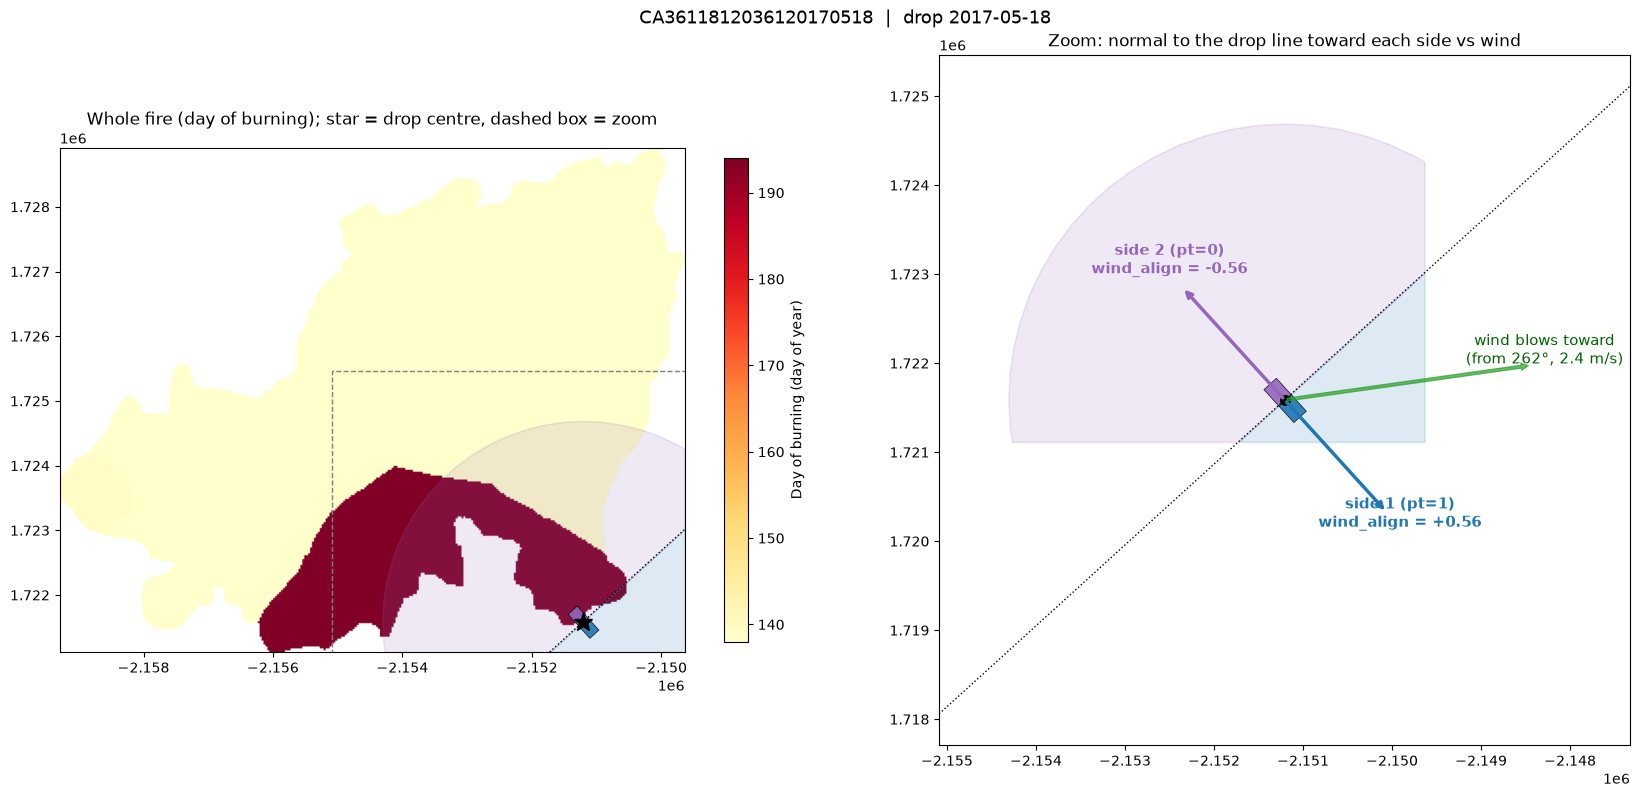

In [47]:
test_drop_id = drops["drop_id"].iloc[5049]

plot_wind_drop(drops[drops["drop_id"] == test_drop_id])

wind hypothesis: 100%|██████████| 10522/10522 [00:27<00:00, 385.65it/s]


10337 drops | protected side is DOWNWIND in 45.7%  (95% CI 44.7% to 46.6%, p = 9.8e-19)
  > 50% would support 'protected = downwind'; < 50% means protected is UPWIND

                count    pct     lo     hi
bin                                       
(-0.001, 0.25]   1816  0.492  0.469  0.515
(0.25, 0.5]      1791  0.458  0.435  0.482
(0.5, 0.75]      2190  0.442  0.422  0.464
(0.75, 1.0]      4540  0.448  0.434  0.463


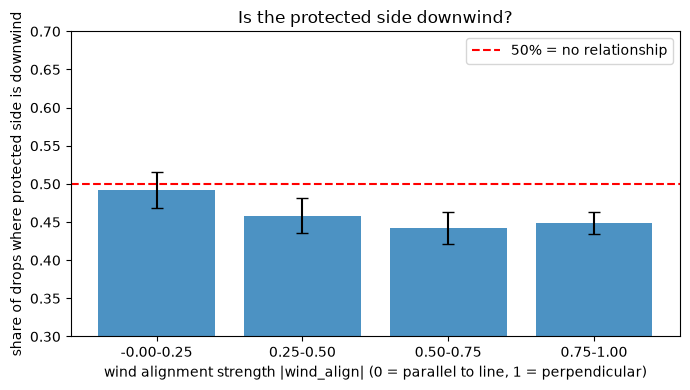

In [45]:
# ---- Hypothesis test: is the protected side (pt=1) the DOWNWIND side? ----
# One row per drop (so the two mirror-image sides are not double counted).
from tqdm import tqdm
from scipy.stats import binomtest
import matplotlib.pyplot as plt

recs = []
for did, pair in tqdm(drops.groupby("drop_id"), desc="wind hypothesis"):
    if len(pair) != 2 or set(pair["buff_id"].astype(int)) != {1, 2}:
        continue
    rows = extract_wind_features(pair)
    if rows is None:
        continue
    pt = pair.set_index(pair["buff_id"].astype(int))["new_pt"]
    if pt.sum() != 1:                          # need exactly one protected side
        continue
    prot = int(pt.idxmax())                    # buff_id of the protected side
    align = {r["buff_id"]: r["wind_align"] for r in rows}
    recs.append({"drop_id": did, "align_prot": align[prot], "speed": rows[0]["wind_speed"]})

t = pd.DataFrame(recs)
t["prot_downwind"] = t["align_prot"] > 0       # +align = side is downwind of the drop line
t["strength"] = t["align_prot"].abs()          # 0 = wind parallel to the line, 1 = wind perpendicular to it

# overall: H0 = protected side is downwind half the time
k, n = int(t["prot_downwind"].sum()), len(t)
r = binomtest(k, n, 0.5)
ci = r.proportion_ci(0.95)
print(f"{n} drops | protected side is DOWNWIND in {k/n:.1%}  (95% CI {ci.low:.1%} to {ci.high:.1%}, p = {r.pvalue:.2g})")
print("  > 50% would support 'protected = downwind'; < 50% means protected is UPWIND\n")

# does it get stronger when the wind is more perpendicular to the drop line?
bins = [0, 0.25, 0.5, 0.75, 1.0]
t["bin"] = pd.cut(t["strength"], bins, include_lowest=True)
g = t.groupby("bin", observed=True)["prot_downwind"].agg(["sum", "count"])
g["pct"] = g["sum"] / g["count"]
g[["lo", "hi"]] = [binomtest(int(s), int(c), 0.5).proportion_ci(0.95)[:2] for s, c in zip(g["sum"], g["count"])]
print(g[["count", "pct", "lo", "hi"]].round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(g))
ax.bar(x, g["pct"], color="tab:blue", alpha=.8)
ax.errorbar(x, g["pct"], yerr=[g["pct"] - g["lo"], g["hi"] - g["pct"]], fmt="none", color="k", capsize=4)
ax.axhline(0.5, color="r", ls="--", label="50% = no relationship")
ax.set_xticks(x); ax.set_xticklabels([f"{i.left:.2f}-{i.right:.2f}" for i in g.index])
ax.set_xlabel("wind alignment strength |wind_align| (0 = parallel to line, 1 = perpendicular)")
ax.set_ylabel("share of drops where protected side is downwind"); ax.set_ylim(0.3, 0.7); ax.legend()
ax.set_title("Is the protected side downwind?"); plt.tight_layout(); plt.show()